# Assignment 2: The Bookstore Intelligence Mission


**Website scraped:** https://books.toscrape.com/

# Mission 1: Reconnaissance

| Data Needed | HTML Tag / Class Found | Your Notes |
|---|---|---|
| Book Title | `<a href="catalogue/a-light-in-the-attic_1000/index.html" title="A Light in the Attic">A Light in the ...</a>` | The visible text is cut off with “...”, so the full title is in the title attribute |
| Price | `<p class="price_color">` | Text looks like £51.77, so the £ symbol must be removed |
| Rating | `<p class="star-rating Three">` | The rating is a word in the second class name (One to Five) |
| Availability | `<p class="instock availability">` | Text has extra whitespace around “In stock” |

**Which tag holds one whole book "card"?**
`<article class="product_pod">`

# Mission 2: Capture the Data

In [ ]:
import re
import time
from urllib.parse import urljoin

import requests
from bs4 import BeautifulSoup
import pandas as pd

In [ ]:
url = "https://books.toscrape.com/catalogue/page-1.html"
response = requests.get(url, timeout=10)
response.encoding = "utf-8"
print("Status code:", response.status_code)

Status code: 200


In [ ]:
soup = BeautifulSoup(response.text, "html.parser")
cards = soup.find_all("article", class_="product_pod")
print("Number of books found on page 1:", len(cards))

Number of books found on page 1: 20


In [ ]:
card = cards[0]

title = card.h3.a["title"]
price_text = card.find("p", class_="price_color").text
price = float(re.sub(r"[^\d.]", "", price_text))
rating_word = card.find("p", class_="star-rating")["class"][1]
availability = card.find("p", class_="availability").get_text(strip=True)

print("Title:       ", title)
print("Price text:  ", price_text)
print("Price number:", price)
print("Rating word: ", rating_word)
print("Availability:", availability)

Title:        A Light in the Attic
Price text:   £51.77
Price number: 51.77
Rating word:  Three
Availability: In stock


In [ ]:
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
print(rating_word, "→", RATING_MAP[rating_word])

Three → 3


In [ ]:
books = []
for card in cards:
    books.append({
        "Title": card.h3.a["title"],
        "Price": float(re.sub(r"[^\d.]", "", card.find("p", class_="price_color").text)),
        "Rating": RATING_MAP[card.find("p", class_="star-rating")["class"][1]],
        "Availability": card.find("p", class_="availability").get_text(strip=True),
    })

df_page1 = pd.DataFrame(books)
df_page1

,Title,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock
5,The Requiem Red,22.65,1,In stock
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4,In stock
7,The Coming Woman: A Novel Based on the Life of...,17.93,3,In stock
8,The Boys in the Boat: Nine Americans and Their...,22.60,4,In stock
9,The Black Maria,52.15,1,In stock


# Mission 3: Scale the Operation

In [ ]:
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

def scrape_page(page_number):
    url = f"https://books.toscrape.com/catalogue/page-{page_number}.html"
    response = requests.get(url, timeout=10)
    response.encoding = "utf-8"

    if response.status_code != 200:
        return []

    soup = BeautifulSoup(response.text, "html.parser")
    page_books = []

    for card in soup.find_all("article", class_="product_pod"):
        page_books.append({
            "Title": card.h3.a["title"],
            "Price": float(re.sub(r"[^\d.]", "", card.find("p", class_="price_color").text)),
            "Rating": RATING_MAP[card.find("p", class_="star-rating")["class"][1]],
            "Availability": card.find("p", class_="availability").get_text(strip=True),
            "URL": urljoin(url, card.h3.a["href"]),
        })
    return page_books

In [ ]:
all_books = []

for page in range(1, 6):
    print(f"Scraping page {page}...")
    all_books.extend(scrape_page(page))
    time.sleep(1)

df = pd.DataFrame(all_books)

Scraping page 1...
Scraping page 2...
Scraping page 3...
Scraping page 4...
Scraping page 5...


In [ ]:
display(df.head(10))
print("Shape (rows, columns):", df.shape)
print()
print(df.dtypes)
print()
print("Missing values per column:")
print(df.isnull().sum())

,Title,Price,Rating,Availability,URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,22.65,1,In stock,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4,In stock,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,17.93,3,In stock,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,22.60,4,In stock,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,52.15,1,In stock,https://books.toscrape.com/catalogue/the-black...


Shape (rows, columns): (100, 5)

Title            object
Price           float64
Rating            int64
Availability     object
URL              object
dtype: object

Missing values per column:
Title           0
Price           0
Rating          0
Availability    0
URL             0
dtype: int64


In [ ]:
df.to_csv("competitor_books.csv", index=False)
pd.read_csv("competitor_books.csv").head()

,Title,Price,Rating,Availability,URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


# Mission 4: Intelligence Analysis

### Q1. Which scraped book is the most expensive?

In [ ]:
print(df.loc[df["Price"].idxmax(), ["Title", "Price"]])

Title    The Death of Humanity: and the Case for Life
Price                                           58.11
Name: 68, dtype: object


**Answer:** The book death of humanity is the most expensive at 58.11

### Q2. Which scraped book is the cheapest?

In [ ]:
print(df.loc[df["Price"].idxmin(), ["Title", "Price"]])

Title    Patience
Price       10.16
Name: 84, dtype: object


**Answer:** the book patience is the cheapest of them all at only 10.16

### Q3. What is the average book price?

In [ ]:
print("Average price: £", round(df["Price"].mean(), 2))

Average price: £ 34.56


**Answer:** the average book price after rounding is 35

### Q4. How many books have a 5-star rating?

In [ ]:
print("5-star books:", (df["Rating"] == 5).sum())

5-star books: 19


**Answer:** 19 books have 5 full five star rating

### Q5. What percentage of the scraped books are in stock?

In [ ]:
pct_in_stock = (df["Availability"] == "In stock").mean() * 100
print(f"In stock: {pct_in_stock:.1f}%")

In stock: 100.0%


**Answer:** 100% the sandbox website shows all in stock so it will always be 100%

### Q6. What are the Top 5 highest-rated books?

In [ ]:
top5 = df.sort_values(["Rating", "Price"], ascending=[False, True]).head(5)
display(top5[["Title", "Rating", "Price"]])

,Title,Rating,Price
81,Princess Between Worlds (Wide-Awake Princess #5),5,13.34
80,"Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...",5,13.61
34,Sophie's World,5,15.94
54,Thirst,5,17.27
12,Set Me Free,5,17.46


**Answer:**

| # | Title | Rating |
|---|---|---|
| 1 | Princess Between Worlds (Wide-Awake Princess #5) | 5 |
| 2 | Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Princess Jellyfish 2-in-1 Omnibus #1) | 5 |
| 3 | Sophie's World | 5 |
| 4 | Thirst | 5 |
| 5 | Set me Free | 5 |

*Note: many books are tied at 5 stars, so I broke ties by choosing the lowest price.*

### Q7. Among the 5-star books, which one is the cheapest?

In [ ]:
five_star = df[df["Rating"] == 5]
print(five_star.loc[five_star["Price"].idxmin(), ["Title", "Price"]])

Title    Princess Between Worlds (Wide-Awake Princess #5)
Price                                               13.34
Name: 81, dtype: object


**Answer:** Among the top rated princess between worlds is the cheapest at 13.34

# Business Decision
**Manager's question:** If you were launching a competing online bookstore, which books from your scraped dataset would you prioritise and why? Use at least TWO pieces of evidence.

In [ ]:
print("Number of books at each rating:")
print(df["Rating"].value_counts().sort_index())

print("\nAverage price at each rating:")
print(df.groupby("Rating")["Price"].mean().round(2))

high_rated_share = (df["Rating"] >= 4).mean() * 100
print(f"\nShare of books rated 4 or 5 stars: {high_rated_share:.1f}%")
print("Overall average price: £", round(df["Price"].mean(), 2))

Number of books at each rating:
Rating
1    22
2    19
3    22
4    18
5    19
Name: count, dtype: int64

Average price at each rating:
Rating
1    35.52
2    35.91
3    36.84
4    33.98
5    30.01
Name: Price, dtype: float64

Share of books rated 4 or 5 stars: 37.0%
Overall average price: £ 34.56


### My recommendation
I would prioritise 4- and 5-star books priced below the average of 34.5£. In my dataset, 37% of books are rated 4 or 5 stars, so there is plenty of well-liked stock to source, and the average 5-star book costs 30£, which is lower than the overall average of 34£. This means high-quality books don’t need to cost more, so we can offer strong customer satisfaction at competitive prices.

# Final Challenge: The CEO Has £100
**Goal:** choose books that maximise the **total star rating** without spending more than **£100**.

In [ ]:
df["StarsPerPound"] = df["Rating"] / df["Price"]
ranked = df.sort_values("StarsPerPound", ascending=False)

total_cost = 0
selected = []
for i, row in ranked.iterrows():
    if total_cost + row["Price"] <= 100:
        selected.append(i)
        total_cost += row["Price"]

choice_A = df.loc[selected]
display(choice_A[["Title", "Price", "Rating"]])
print("Number of books:", len(choice_A))
print("Total cost: £", round(choice_A["Price"].sum(), 2))
print("Total stars:", choice_A["Rating"].sum())

,Title,Price,Rating
81,Princess Between Worlds (Wide-Awake Princess #5),13.34,5
80,"Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...",13.61,5
34,Sophie's World,15.94,5
84,Patience,10.16,3
54,Thirst,17.27,5
12,Set Me Free,17.46,5


Number of books: 6
Total cost: £ 87.78
Total stars: 28


I selected the books with the highest stars per pound until the budget was used. Five of the six books are 5-star titles priced between £13 and £18. Patience which is 3 stars is included because it is the cheapest book in the dataset at £10.16 and still has a good stars-per-pound ratio.

### Bonus 3: Count of books at each star level

In [ ]:
rating_counts = df["Rating"].value_counts().sort_index()
print(rating_counts)

Rating
1    22
2    19
3    22
4    18
5    19
Name: count, dtype: int64


### Bonus 4: Bar chart of rating counts

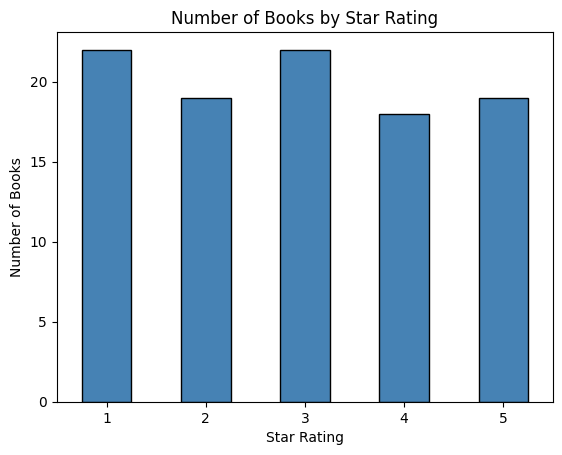

In [ ]:
import matplotlib.pyplot as plt

rating_counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Number of Books by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.show()